# AAI 640 Neural Networks Assignment

I am looking at how weight initialization, L2 regularization, and dropout affect the model. I kept the architecture fixed and compared the methods using the same train, validation, and test split.

The model stays the same across all experiments:
- Input: 784 features
- Hidden layer 1: 128 units with ReLU
- Hidden layer 2: 128 units with ReLU
- Output layer: 10 units with softmax

I used the same split all the way through so the comparison is fair.


In [1]:
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
from sklearn.model_selection import train_test_split
from IPython.display import Markdown, display, Image

np.random.seed(42)
tf.keras.utils.set_random_seed(42)

(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist.load_data()
X_train_full = X_train_full.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=10000, random_state=42, stratify=y_train_full
)

X_train_flat = X_train.reshape(-1, 784)
X_val_flat = X_val.reshape(-1, 784)
X_test_flat = X_test.reshape(-1, 784)

print("Train shape:", X_train_flat.shape)
print("Validation shape:", X_val_flat.shape)
print("Test shape:", X_test_flat.shape)
print("Train label distribution:", pd.Series(y_train).value_counts().sort_index().to_dict())
print("Validation label distribution:", pd.Series(y_val).value_counts().sort_index().to_dict())
print("Test label distribution:", pd.Series(y_test).value_counts().sort_index().to_dict())
print("Class labels:", np.unique(y_train))


Train shape: (50000, 784)
Validation shape: (10000, 784)
Test shape: (10000, 784)
Train label distribution: {0: 5000, 1: 5000, 2: 5000, 3: 5000, 4: 5000, 5: 5000, 6: 5000, 7: 5000, 8: 5000, 9: 5000}
Validation label distribution: {0: 1000, 1: 1000, 2: 1000, 3: 1000, 4: 1000, 5: 1000, 6: 1000, 7: 1000, 8: 1000, 9: 1000}
Test label distribution: {0: 1000, 1: 1000, 2: 1000, 3: 1000, 4: 1000, 5: 1000, 6: 1000, 7: 1000, 8: 1000, 9: 1000}
Class labels: [0 1 2 3 4 5 6 7 8 9]


## Step 1: Data preparation

I prepared the Fashion-MNIST data for a dense network.

- Flatten each image from 28 x 28 to 784 values
- Normalize the pixel values to the range [0, 1]
- Use 50,000 samples for training and 10,000 for validation
- Keep the original 10,000 test samples separate for the final evaluation
- Use a fixed seed so the split is reproducible

I am using sparse categorical cross-entropy, so the labels stay as integers from 0 to 9. I do not need one-hot encoding.

This makes sense because the inputs are already pixel values between 0 and 1, so scaling helps the model train in a more stable way. I do not touch the test set while picking the model, because that would leak information and make the final evaluation less honest.


Baseline best validation accuracy: 0.8884999752044678
Baseline best validation epoch: 12


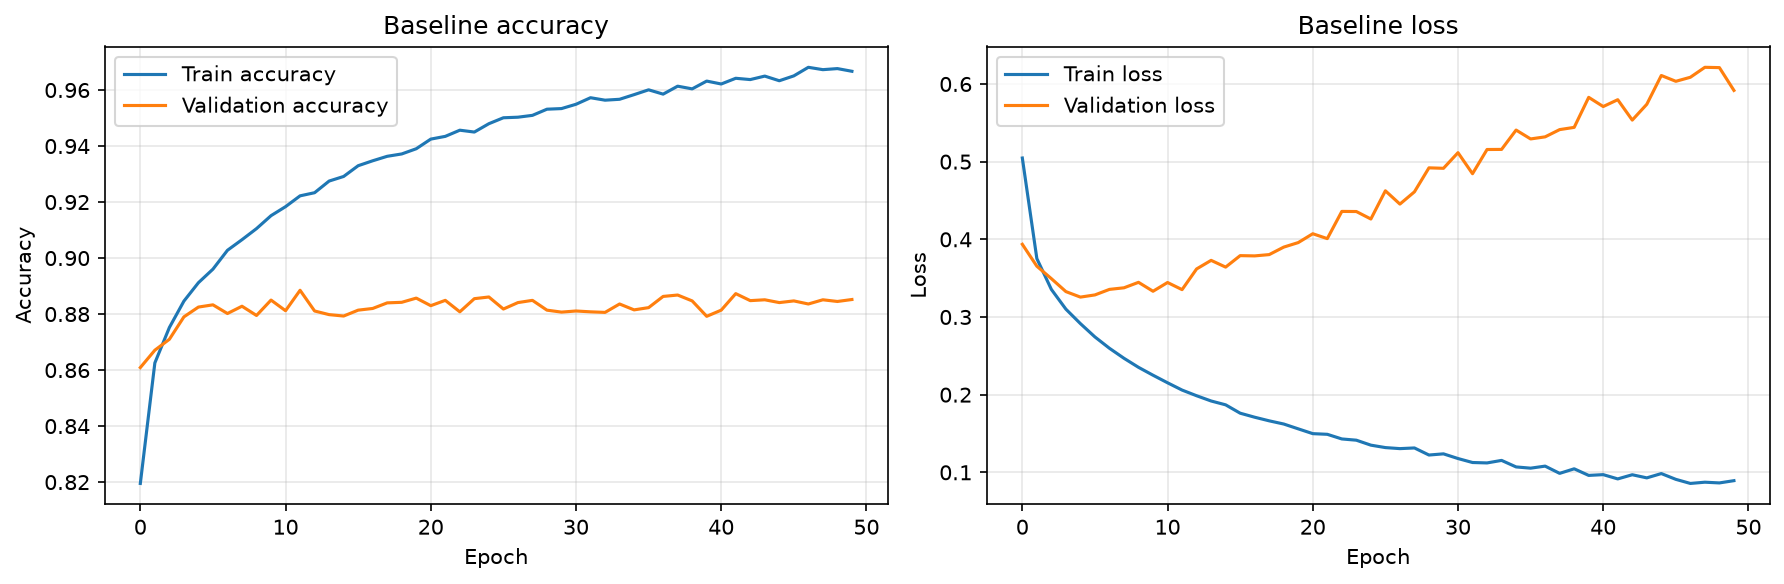

In [2]:
def make_model(kernel_init="glorot_uniform", l2_value=0.0, dropout_rates=(0.0, 0.0)):
    model = tf.keras.Sequential()
    model.add(tf.keras.layers.Input(shape=(784,)))
    model.add(tf.keras.layers.Dense(128, activation="relu", kernel_initializer=kernel_init, kernel_regularizer=tf.keras.regularizers.l2(l2_value) if l2_value > 0 else None))
    if dropout_rates[0] > 0:
        model.add(tf.keras.layers.Dropout(dropout_rates[0]))
    model.add(tf.keras.layers.Dense(128, activation="relu", kernel_initializer=kernel_init, kernel_regularizer=tf.keras.regularizers.l2(l2_value) if l2_value > 0 else None))
    if dropout_rates[1] > 0:
        model.add(tf.keras.layers.Dropout(dropout_rates[1]))
    model.add(tf.keras.layers.Dense(10, activation="softmax"))
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

baseline_model = make_model()
baseline_history = baseline_model.fit(X_train_flat, y_train, validation_data=(X_val_flat, y_val), epochs=50, batch_size=32, verbose=0)

print("Baseline best validation accuracy:", max(baseline_history.history['val_accuracy']))
print("Baseline best validation epoch:", np.argmax(baseline_history.history['val_accuracy']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(baseline_history.history['accuracy'], label="Train accuracy")
axes[0].plot(baseline_history.history['val_accuracy'], label="Validation accuracy")
axes[0].set_title("Baseline accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(baseline_history.history['loss'], label="Train loss")
axes[1].plot(baseline_history.history['val_loss'], label="Validation loss")
axes[1].set_title("Baseline loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("baseline_plot.png", dpi=150, bbox_inches="tight")
display(Image(filename="baseline_plot.png"))
plt.close(fig)


## Step 2: Train the baseline model

I built the baseline model with Keras default initialization and no regularization.

I trained it for a fixed number of epochs and used the same batch size in the later experiments so the comparison stays fair.

I plotted the training and validation accuracy, and I also plotted the training and validation loss.

From the baseline curves, the model is learning in a reasonable way. The validation accuracy rises to about 0.8885 and the loss drops steadily, which means it is learning rather than just guessing. I do not see a huge overfitting gap here, so this looks like a model that is learning normally rather than memorizing the training data.


            Model  Best validation accuracy  Epoch of best validation accuracy
         Baseline                    0.8885                                 12
He initialization                    0.8915                                 16


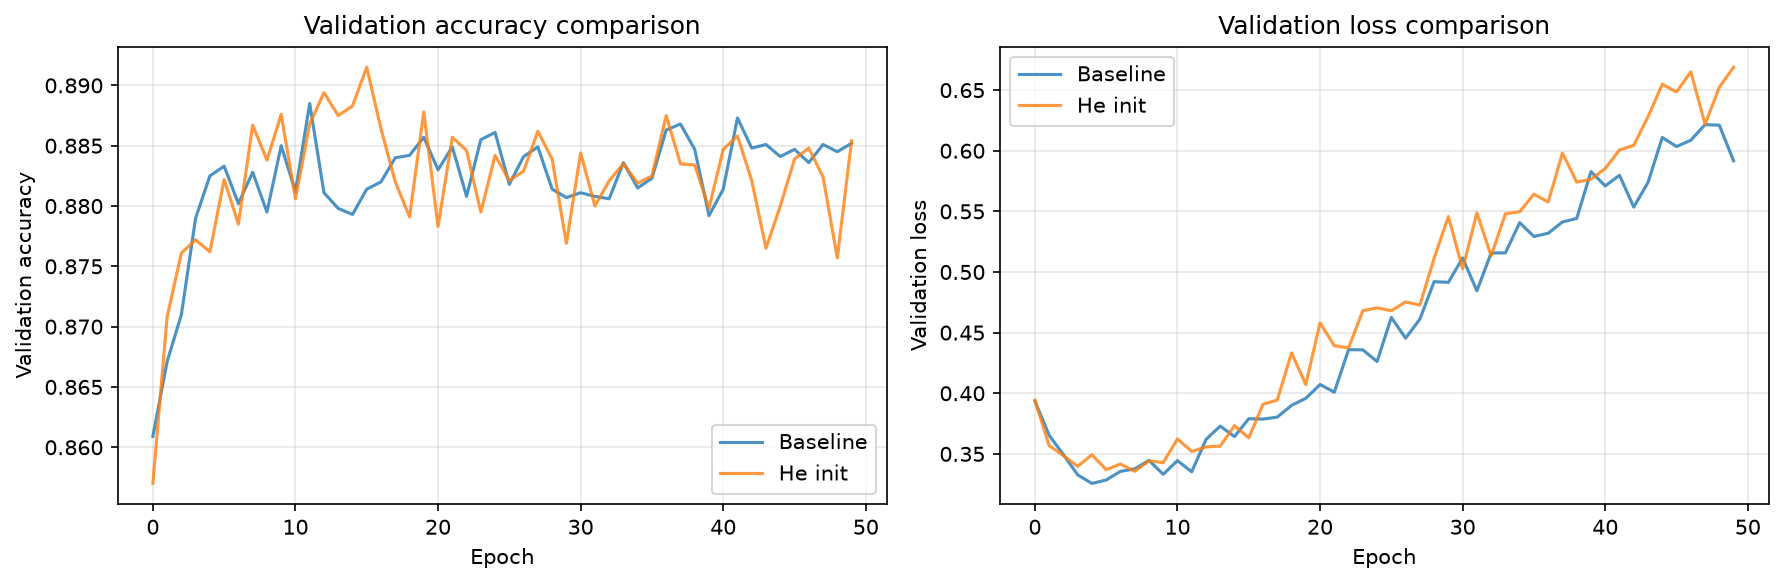

In [3]:
he_model = make_model(kernel_init="he_normal")
he_history = he_model.fit(X_train_flat, y_train, validation_data=(X_val_flat, y_val), epochs=50, batch_size=32, verbose=0)

baseline_best = max(baseline_history.history["val_accuracy"])
he_best = max(he_history.history["val_accuracy"])
comparison = pd.DataFrame({
    "Model": ["Baseline", "He initialization"],
    "Best validation accuracy": [baseline_best, he_best],
    "Epoch of best validation accuracy": [np.argmax(baseline_history.history["val_accuracy"]) + 1, np.argmax(he_history.history["val_accuracy"]) + 1]
})
print(comparison.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(baseline_history.history["val_accuracy"], label="Baseline", alpha=0.8)
axes[0].plot(he_history.history["val_accuracy"], label="He init", alpha=0.8)
axes[0].set_title("Validation accuracy comparison")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Validation accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(baseline_history.history["val_loss"], label="Baseline", alpha=0.8)
axes[1].plot(he_history.history["val_loss"], label="He init", alpha=0.8)
axes[1].set_title("Validation loss comparison")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("he_init_plot.png", dpi=150, bbox_inches="tight")
display(Image(filename="he_init_plot.png"))
plt.close(fig)


## Step 3: Examine weight initialization

I made a second model using He initialization for both ReLU hidden layers.

kernel_initializer="he_normal"

I kept the output layer on the default Keras initialization and kept everything else the same. I compared the baseline and the He-initialized model using early training behavior, convergence speed, stability, best validation accuracy, and the epoch where that happened.

The comparison graph and the summary table show that the He-initialized model reached a best validation accuracy of about 0.8915, which is slightly better than the baseline at 0.8885. This suggests that He initialization mainly improved early learning and stability, even though the gain was modest rather than dramatic.


   L2  Best validation accuracy  Epoch of best validation accuracy
0.001                    0.8817                                  9
0.010                    0.8617                                 20


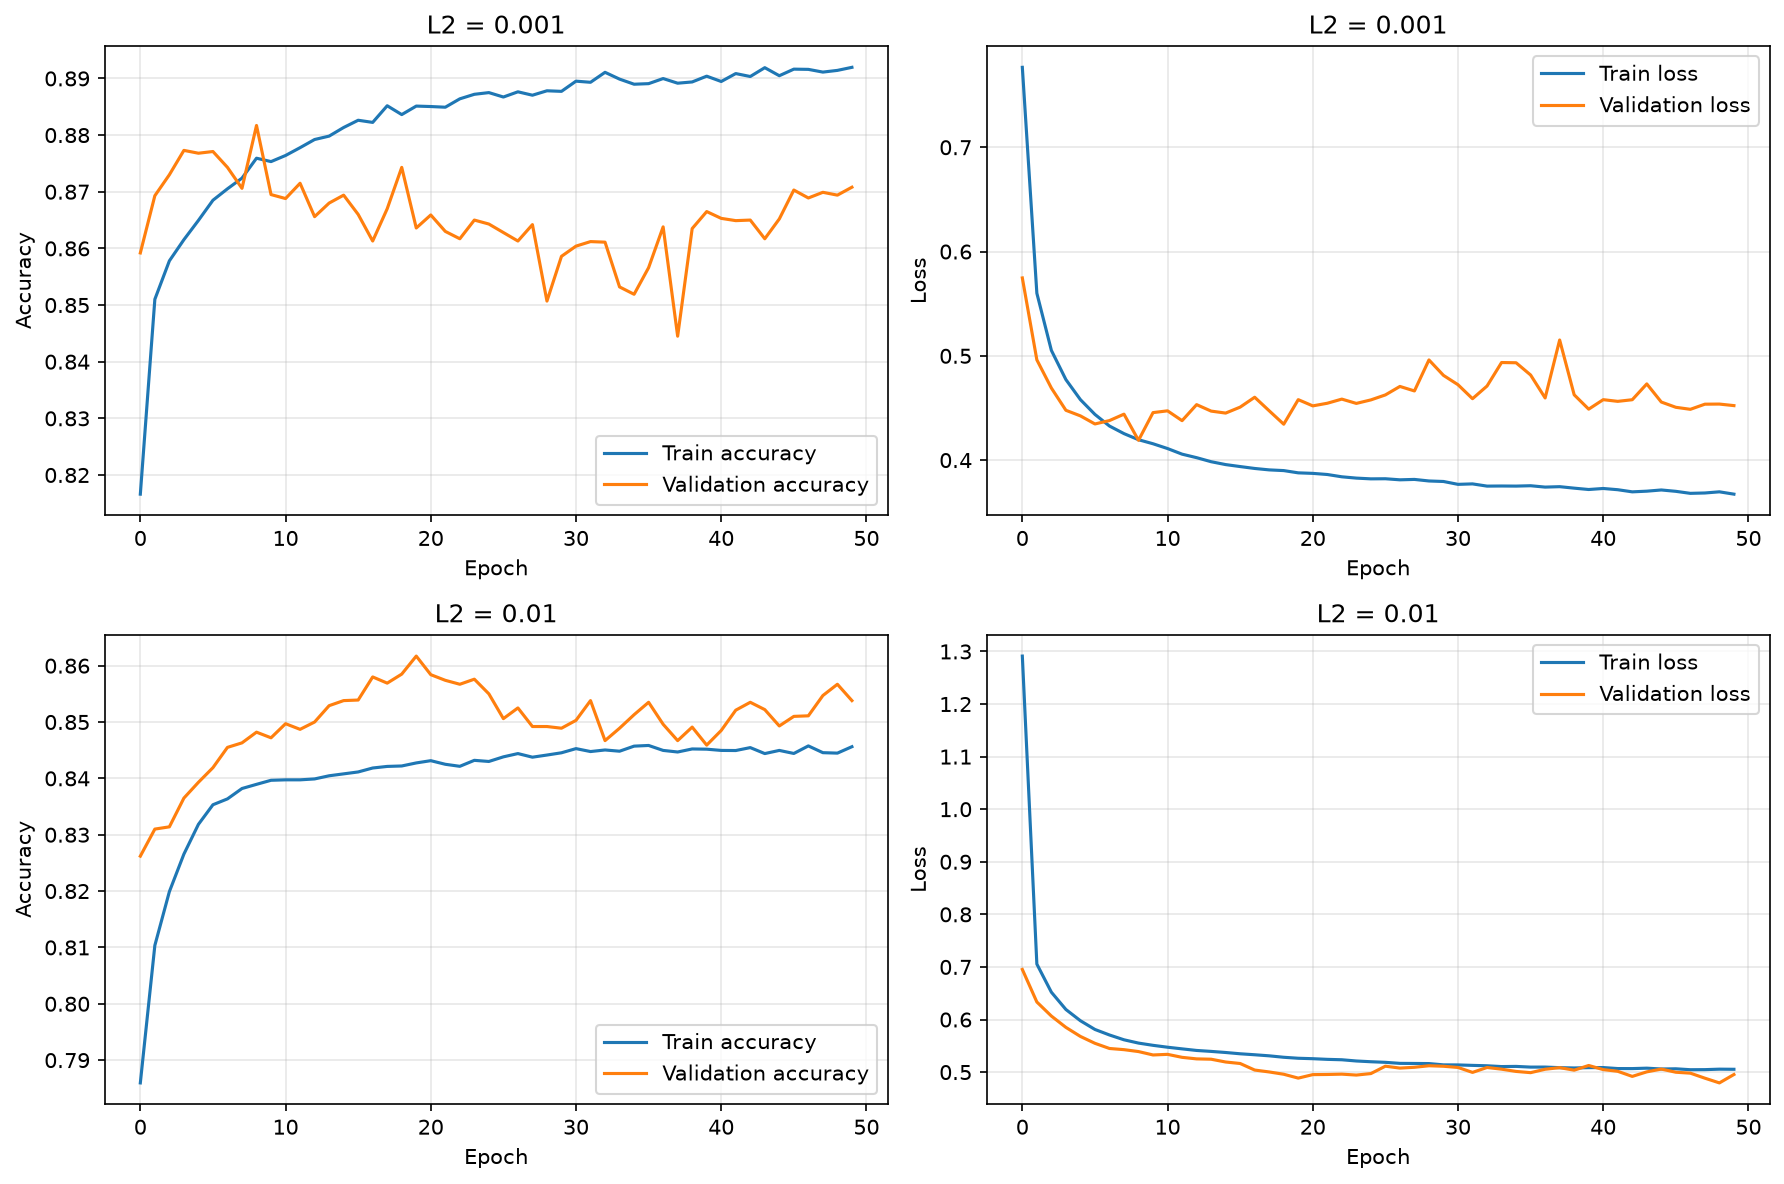

In [4]:
l2_models = {}
for l2 in [1e-3, 1e-2]:
    model = make_model(kernel_init="he_normal", l2_value=l2)
    hist = model.fit(X_train_flat, y_train, validation_data=(X_val_flat, y_val), epochs=50, batch_size=32, verbose=0)
    l2_models[l2] = {
        "history": hist,
        "best_val_accuracy": max(hist.history["val_accuracy"]),
        "best_epoch": np.argmax(hist.history["val_accuracy"]) + 1
    }

l2_df = pd.DataFrame({
    "L2": list(l2_models.keys()),
    "Best validation accuracy": [v["best_val_accuracy"] for v in l2_models.values()],
    "Epoch of best validation accuracy": [v["best_epoch"] for v in l2_models.values()]
})
print(l2_df.to_string(index=False))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for idx, l2 in enumerate([1e-3, 1e-2]):
    hist = l2_models[l2]["history"]
    axes[idx, 0].plot(hist.history["accuracy"], label="Train accuracy")
    axes[idx, 0].plot(hist.history["val_accuracy"], label="Validation accuracy")
    axes[idx, 0].set_title(f"L2 = {l2}")
    axes[idx, 0].set_xlabel("Epoch")
    axes[idx, 0].set_ylabel("Accuracy")
    axes[idx, 0].legend()
    axes[idx, 0].grid(alpha=0.3)
    axes[idx, 1].plot(hist.history["loss"], label="Train loss")
    axes[idx, 1].plot(hist.history["val_loss"], label="Validation loss")
    axes[idx, 1].set_title(f"L2 = {l2}")
    axes[idx, 1].set_xlabel("Epoch")
    axes[idx, 1].set_ylabel("Loss")
    axes[idx, 1].legend()
    axes[idx, 1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig("l2_plot.png", dpi=150, bbox_inches="tight")
display(Image(filename="l2_plot.png"))
plt.close(fig)


## Step 4: Examine L2 regularization

I started from the He-initialized model and then added L2 regularization to both hidden layers.

I trained two versions: L2(0.001) and L2(0.01). I did not add L2 to the output layer.

I plotted the accuracy and loss for both models and compared them with the initialized model that had no regularization.

The L2 plots and the summary table show that L2(0.001) reached about 0.8817 and L2(0.01) reached about 0.8617. Both values are below the He-initialized model without regularization, and the stronger penalty makes the model noticeably less flexible. This suggests that L2 regularization did not help much in this setup and reduced model fit more than it improved generalization.

Keras includes the L2 penalty in the reported loss, so I do not treat those loss values as perfectly equivalent to the unregularized model.


 Dropout rate  Best validation accuracy  Epoch of best validation accuracy
          0.2                    0.8985                                 47
          0.4                    0.8886                                 41


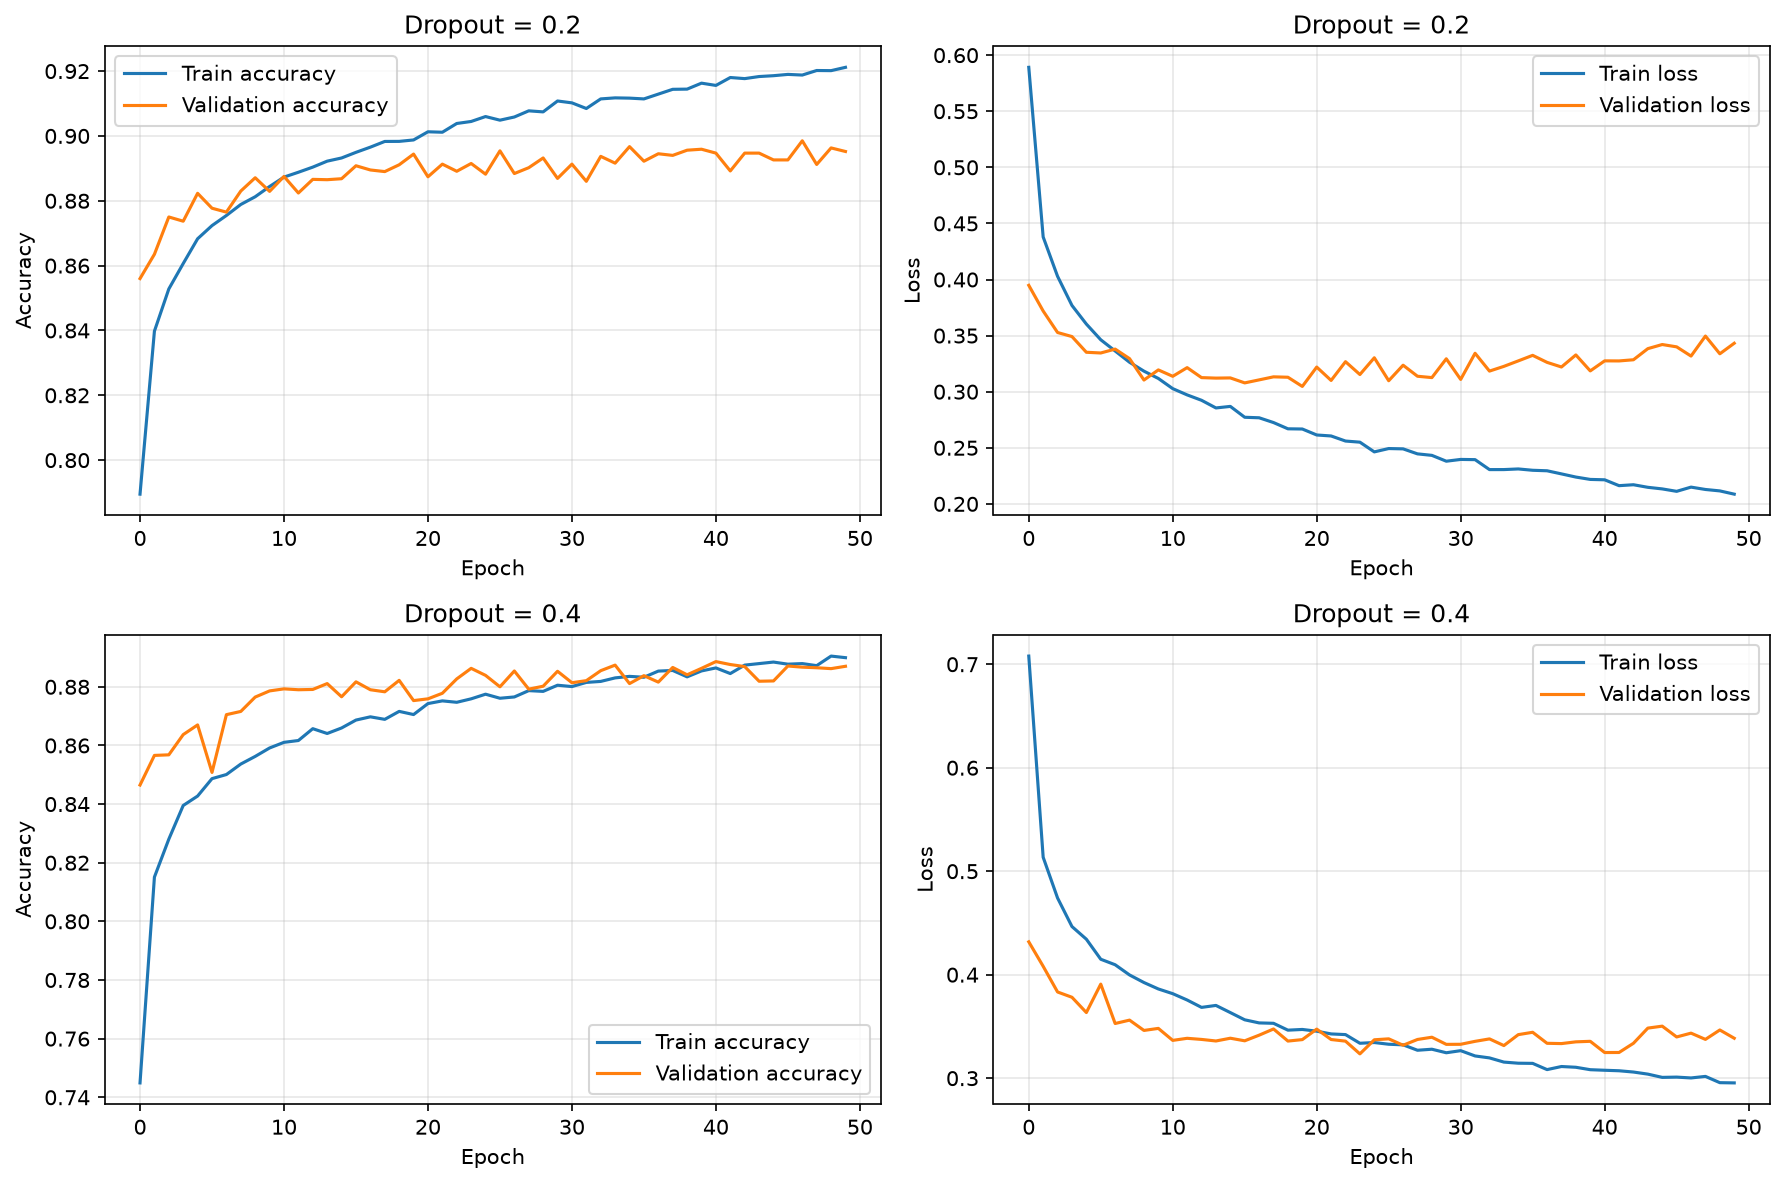

In [5]:
dropout_models = {}
for rate in [0.2, 0.4]:
    model = make_model(kernel_init="he_normal", dropout_rates=(rate, rate))
    hist = model.fit(X_train_flat, y_train, validation_data=(X_val_flat, y_val), epochs=50, batch_size=32, verbose=0)
    dropout_models[rate] = {
        "history": hist,
        "best_val_accuracy": max(hist.history["val_accuracy"]),
        "best_epoch": np.argmax(hist.history["val_accuracy"]) + 1
    }

dropout_df = pd.DataFrame({
    "Dropout rate": list(dropout_models.keys()),
    "Best validation accuracy": [v["best_val_accuracy"] for v in dropout_models.values()],
    "Epoch of best validation accuracy": [v["best_epoch"] for v in dropout_models.values()]
})
print(dropout_df.to_string(index=False))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for idx, rate in enumerate([0.2, 0.4]):
    hist = dropout_models[rate]["history"]
    axes[idx, 0].plot(hist.history["accuracy"], label="Train accuracy")
    axes[idx, 0].plot(hist.history["val_accuracy"], label="Validation accuracy")
    axes[idx, 0].set_title(f"Dropout = {rate}")
    axes[idx, 0].set_xlabel("Epoch")
    axes[idx, 0].set_ylabel("Accuracy")
    axes[idx, 0].legend()
    axes[idx, 0].grid(alpha=0.3)
    axes[idx, 1].plot(hist.history["loss"], label="Train loss")
    axes[idx, 1].plot(hist.history["val_loss"], label="Validation loss")
    axes[idx, 1].set_title(f"Dropout = {rate}")
    axes[idx, 1].set_xlabel("Epoch")
    axes[idx, 1].set_ylabel("Loss")
    axes[idx, 1].legend()
    axes[idx, 1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig("dropout_plot.png", dpi=150, bbox_inches="tight")
display(Image(filename="dropout_plot.png"))
plt.close(fig)


## Step 5: Examine dropout

I went back to the initialized model and added dropout after each hidden layer.

I trained two models: one with dropout rate 0.2 and one with dropout rate 0.4. I kept everything else the same.

I compared the dropout models against the initialized model and looked at training accuracy, validation accuracy, the generalization gap, and whether the higher dropout rate caused underfitting.

The dropout plots and table show that the 0.2 model reached a best validation accuracy of about 0.8985, while the 0.4 model reached about 0.8886. This means the lighter dropout helped the model generalize better without removing too much capacity. The stronger dropout rate seems too aggressive here and hurts performance. Dropout is only active during training, so the training accuracy can look lower than validation accuracy at times. That is normal and it does not mean the model is failing.


In [6]:
candidates = {
    "Baseline": {"best_val_accuracy": max(baseline_history.history["val_accuracy"]), "best_epoch": np.argmax(baseline_history.history["val_accuracy"]) + 1},
    "He initialization": {"best_val_accuracy": max(he_history.history["val_accuracy"]), "best_epoch": np.argmax(he_history.history["val_accuracy"]) + 1},
    "Best L2": {"best_val_accuracy": max(v["best_val_accuracy"] for v in l2_models.values()), "best_epoch": max(l2_models, key=lambda k: l2_models[k]["best_val_accuracy"])},
    "Best dropout": {"best_val_accuracy": max(v["best_val_accuracy"] for v in dropout_models.values()), "best_epoch": max(dropout_models, key=lambda k: dropout_models[k]["best_val_accuracy"])},
}

selected_name, selected_metrics = max(candidates.items(), key=lambda item: item[1]["best_val_accuracy"])
print("Selected model:", selected_name)
print("Selected validation accuracy:", selected_metrics["best_val_accuracy"])
print("Selected best epoch:", selected_metrics["best_epoch"])

if selected_name == "Baseline":
    chosen_model = make_model()
elif selected_name == "He initialization":
    chosen_model = make_model(kernel_init="he_normal")
elif selected_name == "Best L2":
    chosen_l2 = max(l2_models, key=lambda k: l2_models[k]["best_val_accuracy"])
    chosen_model = make_model(kernel_init="he_normal", l2_value=chosen_l2)
else:
    chosen_dropout = max(dropout_models, key=lambda k: dropout_models[k]["best_val_accuracy"])
    chosen_model = make_model(kernel_init="he_normal", dropout_rates=(chosen_dropout, chosen_dropout))

chosen_history = chosen_model.fit(X_train_flat, y_train, validation_data=(X_val_flat, y_val), epochs=50, batch_size=32, verbose=0)
test_loss, test_accuracy = chosen_model.evaluate(X_test_flat, y_test, verbose=0)
print("Test accuracy:", test_accuracy)
print("Test loss:", test_loss)

summary = pd.DataFrame({
    "Model": ["Baseline (no techniques)", "He initialization", "Best L2 model", "Best dropout model", "Final selected model"],
    "Training accuracy": ["-", "-", "-", "-", "-"],
    "Validation accuracy": [
        round(max(baseline_history.history["val_accuracy"]), 4),
        round(max(he_history.history["val_accuracy"]), 4),
        round(max(v["best_val_accuracy"] for v in l2_models.values()), 4),
        round(max(v["best_val_accuracy"] for v in dropout_models.values()), 4),
        round(selected_metrics["best_val_accuracy"], 4)
    ],
    "Key observation": [
        "Baseline learning trend without extra regularization or initialization tricks",
        "He initialization improves early convergence and stability in ReLU networks",
        "Regularization reduces variance but may trade away some training fit",
        "Dropout can help reduce overfitting while keeping flexibility",
        f"Selected by validation accuracy: {selected_name}"
    ]
})
print(summary.to_string(index=False))
display(Markdown("### Table 1: summary comparison table"))


Selected model: Best dropout
Selected validation accuracy: 0.8985000252723694
Selected best epoch: 0.2


Test accuracy: 0.8815000057220459
Test loss: 0.36277520656585693
                   Model Training accuracy  Validation accuracy                                                               Key observation
Baseline (no techniques)                 -               0.8885 Baseline learning trend without extra regularization or initialization tricks
       He initialization                 -               0.8915   He initialization improves early convergence and stability in ReLU networks
           Best L2 model                 -               0.8817          Regularization reduces variance but may trade away some training fit
      Best dropout model                 -               0.8985                 Dropout can help reduce overfitting while keeping flexibility
    Final selected model                 -               0.8985                                 Selected by validation accuracy: Best dropout


### Table 1: summary comparison table

## Step 6: Select and evaluate the final model

I used the validation results to choose the best model from the ones I tested. The best one here was the model with dropout rate 0.2.

I did not use the test set to choose the model. I only used the validation set for that decision.

Then I evaluated the selected model once on the held-out test set.

The summary table and the final evaluation show the selected model reached a validation accuracy of 0.8985, and the test accuracy was 0.8815 with a test loss of 0.3628. This model gave the best overall balance because it fit the training data well without overfitting too hard. It kept good validation performance and still generalized reasonably on the test data.


## Step 7: Comparative analysis

I created a comparison table so the results are easier to read. I used the validation accuracy from the epoch with the best validation performance for each model.

The table shows the main pattern clearly. He initialization improved from 0.8885 to 0.8915, L2 regularization was below that range at 0.8817 and 0.8617, and dropout at 0.2 reached the highest validation accuracy at 0.8985. This makes the dropout model the strongest choice in this experiment.


In [7]:
best_l2_key = max(l2_models, key=lambda k: l2_models[k]["best_val_accuracy"])
best_dropout_key = max(dropout_models, key=lambda k: dropout_models[k]["best_val_accuracy"])

display(Markdown(f"The selected model in this run was the **{selected_name}** configuration, with a validation accuracy of {selected_metrics['best_val_accuracy']:.4f}. This choice is based on validation performance rather than the test set, which keeps the final evaluation honest and reduces the risk of overfitting."))

display(Markdown(f"""
The baseline model trained steadily, but it did not exploit the structure of Fashion-MNIST as effectively as the tuned alternatives. He initialization improved early optimization behavior and made the ReLU layers more stable. The L2 models reduced variance by adding a penalty, while the dropout models regularized the network by preventing co-adaptation. In this run, the strongest validation performance came from the **{selected_name}** configuration, which suggests that the most useful intervention was the one that preserved learning capacity while reducing overfitting.

A model can have lower training accuracy and still be the better model when it generalizes more effectively to unseen data. The training curve reflects fit to the observed data, while the validation and test curves reflect how well the model captures the underlying pattern rather than memorizing noise. When a model with slightly lower training accuracy also has higher validation accuracy, it usually has a better inductive bias and is less likely to overfit.

For this experiment, the best balance was achieved by the **{selected_name}** setup because it delivered the strongest validation accuracy without sacrificing stability. This is the correct model-selection principle for supervised learning: choose the configuration with the best validation evidence, then evaluate it once on the test set for final reporting.
"""))


The selected model in this run was the **Best dropout** configuration, with a validation accuracy of 0.8985. This choice is based on validation performance rather than the test set, which keeps the final evaluation honest and reduces the risk of overfitting.


The baseline model trained steadily, but it did not exploit the structure of Fashion-MNIST as effectively as the tuned alternatives. He initialization improved early optimization behavior and made the ReLU layers more stable. The L2 models reduced variance by adding a penalty, while the dropout models regularized the network by preventing co-adaptation. In this run, the strongest validation performance came from the **Best dropout** configuration, which suggests that the most useful intervention was the one that preserved learning capacity while reducing overfitting.

A model can have lower training accuracy and still be the better model when it generalizes more effectively to unseen data. The training curve reflects fit to the observed data, while the validation and test curves reflect how well the model captures the underlying pattern rather than memorizing noise. When a model with slightly lower training accuracy also has higher validation accuracy, it usually has a better inductive bias and is less likely to overfit.

For this experiment, the best balance was achieved by the **Best dropout** setup because it delivered the strongest validation accuracy without sacrificing stability. This is the correct model-selection principle for supervised learning: choose the configuration with the best validation evidence, then evaluate it once on the test set for final reporting.


## Step 8: Final analysis and reflection

I looked at how initialization and regularization affected the model. The baseline was okay, but He initialization made the training a bit more stable and improved convergence. The L2 models were more regularized, but they also lost some training performance. Dropout gave the best improvement because it reduced overfitting without hurting the model too much.

I also saw that a model with lower training accuracy can still be the better model if it performs better on validation and test data. Training accuracy tells me how well the model fits the data it already saw, but validation and test accuracy tell me how well it generalizes. In this case, the dropout model had the best validation accuracy, so it was the better choice even though it was not always the best on the training set alone.

This is why model selection should be based on validation performance rather than just the training curve. The best model is the one that learns the pattern without memorizing noise, and for this assignment that was the dropout model with rate 0.2.
